In [1]:
import sys
from pathlib import Path
if Path(sys.executable).resolve() != Path('E:\\Temp\\lastfm-windows-acceptance-20261107\\.venv\\Scripts\\python.exe').resolve():
    raise RuntimeError('Wrong Python kernel')

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / 'src'))
import musicrec.final_evaluation as _acceptance_final
def _reject_final_test_scoring(*args, **kwargs):
    raise RuntimeError('Held-out test scoring is disabled during acceptance')
_acceptance_final.run_final_once = _reject_final_test_scoring
_acceptance_final.evaluate = _reject_final_test_scoring
print('Acceptance guard installed for final test scoring')


Acceptance guard installed for final test scoring


# 冻结决策与独立测试结果

本Notebook查看并核验已经完成的最终一次评估，**不再次训练、不重新读取测试标签、不重新给测试集评分**。所有输出来自真实保存结果及可重复的聚合检查。

主模型在看测试前固定为ItemCF（100邻居，shrinkage=10）。三种神经模型是预先指定的对照，不根据测试挑种子或换赢家。首次实验/干净复现实验由 scripts/freeze_final_decision.py 与 scripts/run_final_once.py 驱动；已完成目录有防止意外再次评估的状态保护。

历史随包输出来自IPython进程内逐格执行。本模板生成新的隔离验收副本，Windows原生Jupyter内核的执行结果与环境见 outputs/windows_native_verification/status.json。AI辅助使用和真实人工贡献需如实披露。

In [3]:
from pathlib import Path
import sys,json,subprocess
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd().resolve()
if not (ROOT/'src/musicrec').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'));sys.path.insert(0,str(ROOT/'scripts'))
from summarize_final import verify_and_summarize
OUT=ROOT/'outputs/final'
decision=json.loads((OUT/'frozen_decision.json').read_text(encoding="utf-8"))
state=json.loads((OUT/'evaluation_state.json').read_text(encoding="utf-8"))
print('主模型:',decision['selected_primary_model'])
display(pd.DataFrame(decision['neural_models']))
display(pd.Series(state,name='persisted_execution_state'))

主模型: {'family': 'itemcf', 'neighbors': 100, 'shrinkage': 10.0}


,family,dim,lr,validation_selected_epochs,final_epochs,seeds
0,bpr_mf,32,0.005,"[4, 8, 4]",4,"[42, 43, 44]"
1,neumf,16,0.003,"[20, 24, 24]",24,"[42, 43, 44]"
2,content_two_tower,32,0.003,"[12, 24, 8]",12,"[42, 43, 44]"


status                                                                    completed
decision_sha256                   24a047dabfa2fffeb57f6c0b38e5191fb73626778c65f4...
refit_started_at_utc                               2026-11-06T08:22:10.189726+00:00
test_labels_read                                                               True
test_metrics_evaluated                                                         True
all_checkpoints_saved_at_utc                       2026-11-06T08:23:06.367698+00:00
checkpoint_count                                                                 11
known_history_rows                                                            83571
known_history_users                                                            1892
known_history_artists                                                         16582
test_evaluation_started_at_utc                     2026-11-06T08:23:06.368065+00:00
completed_at_utc                                   2026-11-06T08:23:55.59231

## 1. 冻结与时间顺序

训练轮数在测试前确定为既有3种子验证所选epoch的中位数：BPR4、NeuMF24、内容12。这一具体规则是在冻结时确定，不假称第一阶段已给出这些数字。

所有模型用相同83,571条 train+validation 已知历史重拟合。神经模型固定42/43/44三个种子，不早停、不选种子。热度、warm/cold与标签词表/IDF均按已知历史重算，测试仍不参与特征。

核验包括冻结证据哈希、11个checkpoint均先于测试阶段保存、固定轮数、逐用户指标与聚合、三种子均值/样本SD。顺序由代码和持久化记录佐证，不是系统级访问审计。

In [4]:
comparison,groups=verify_and_summarize(ROOT)
display(comparison[['model','ndcg@10','ndcg@10_seed_sd','recall@10','precision@10','catalogue_coverage@10','frozen_primary']].round(6))
display(pd.Series(json.loads((OUT/'verification.json').read_text(encoding="utf-8"))))

            model  ndcg@10  ndcg@10_seed_sd  recall@10  catalogue_coverage@10
       popularity 0.065566         0.000000   0.076780               0.001588
           itemcf 0.172136         0.000000   0.175013               0.045599
           bpr_mf 0.086360         0.006245   0.089664               0.004934
            neumf 0.092789         0.003614   0.101749               0.012364
content_two_tower 0.112317         0.003341   0.125144               0.066338


,model,ndcg@10,ndcg@10_seed_sd,recall@10,precision@10,catalogue_coverage@10,frozen_primary
0,popularity,0.065566,0.000000,0.076780,0.037826,0.001588,False
1,itemcf,0.172136,0.000000,0.175013,0.086308,0.045599,True
2,bpr_mf,0.086360,0.006245,0.089664,0.044202,0.004934,False
3,neumf,0.092789,0.003614,0.101749,0.050186,0.012364,False
4,content_two_tower,0.112317,0.003341,0.125144,0.061907,0.066338,False


freeze_and_evidence_hashes                                                                 passed
chronology                                      all eleven checkpoints saved before test was read
checkpoint_hashes                                                                              11
individual_runs_aggregates_verified                                                            11
five_model_mean_and_sample_sd                                                              passed
actual_training_epochs_match_frozen_values                                                   True
primary_model_still_frozen_itemcf                                                            True
test_labels_reread_for_this_verification                                                    False
test_scores_recomputed_for_this_verification                                                False
dtype: object

## 2. 同一独立测试协议

候选为全部17,632艺人目录减去用户 train+validation 历史。1,877测试用户、9,263目标；冷目标不删除。NDCG/Recall/Precision逐用户计算再宏平均。

误差棒是3个固定训练预算种子的样本标准差，不是置信区间；基线为确定性算法。验证期和测试期的训练信息量不同，因此不能把测试比验证更高直接当模型“又改进了一次”。

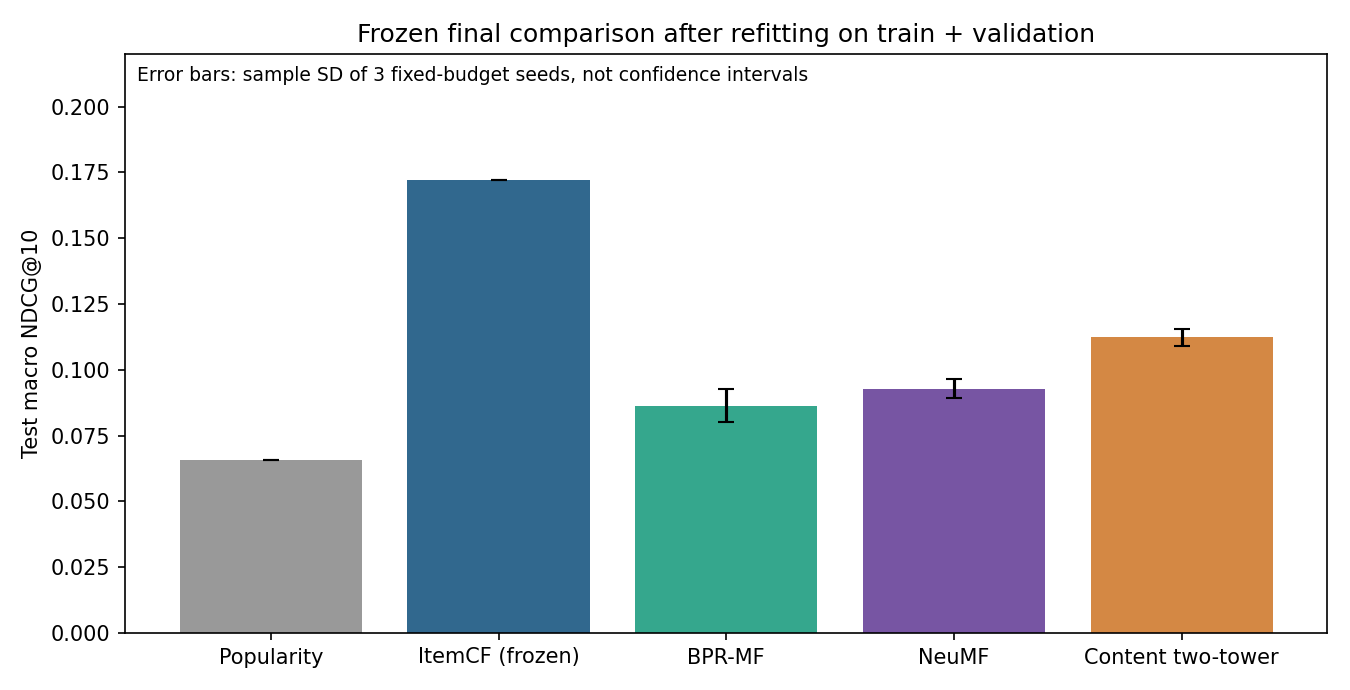

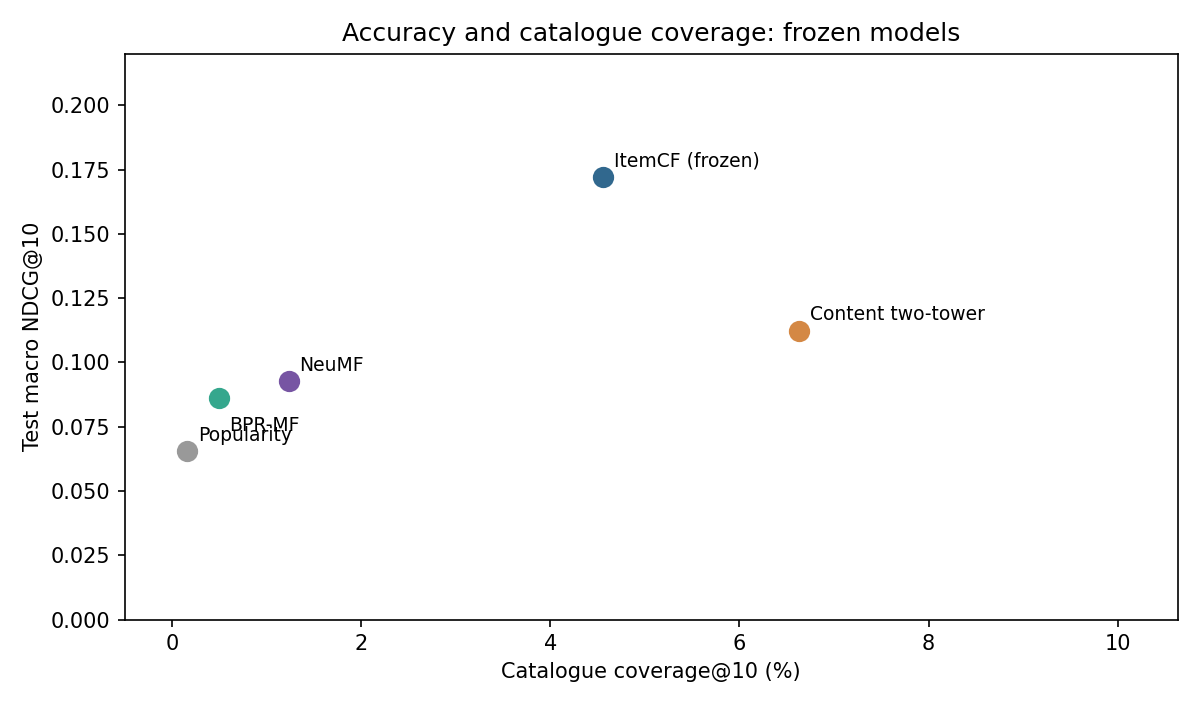

contrast       frozen ItemCF minus Popularity, per-user NDCG@10
mean                                                    0.10657
lower_95                                               0.100018
upper_95                                               0.113839
samples                                                    1000
seed                                                       2026
limitation    conditional on this split and these trained mo...
dtype: object

In [5]:
for name in ['06_final_test_comparison.png','07_test_accuracy_coverage.png']:
    display(Image(filename=str(ROOT/'outputs/figures'/name)))
display(pd.Series(json.loads((OUT/'primary_paired_user_bootstrap.json').read_text(encoding="utf-8"))))

## 3. 分组与内容覆盖

“含冷目标用户”组会同时含warm目标，不等于只对冷艺人算的召回率。低活跃组只有25位，避免扩大解释。标签时间不等于听歌时间，整个任务仍是随机偏好恢复，不是未来下一次听歌预测。

In [6]:
display(groups.round(6))
display(pd.Series(json.loads((OUT/'refit_content_audit.json').read_text(encoding="utf-8")),name='known_history_content'))

,family,group,users,ndcg10_mean,recall10_mean
0,popularity,all,1877,0.065566,0.076780
1,popularity,has_cold_target,675,0.026708,0.032593
2,popularity,all_targets_warm,1202,0.087388,0.101595
3,popularity,known_history_degree_below_30,25,0.046191,0.086667
4,itemcf,all,1877,0.172136,0.175013
5,itemcf,has_cold_target,675,0.089845,0.098370
6,itemcf,all_targets_warm,1202,0.218348,0.218053
7,itemcf,known_history_degree_below_30,25,0.115240,0.186667
8,bpr_mf,all,1877,0.086360,0.089664
9,bpr_mf,has_cold_target,675,0.037780,0.041086


raw_tag_events                                                                186479
outside_catalogue_events                                                        1538
within_catalogue_events                                                       184941
allowed_unique_train_tag_events                                                66078
kept_train_tag_events                                                          59107
vocabulary_size                                                                 2000
artists_with_content                                                            6055
artists_without_content                                                        11577
training_artists                                                               16582
min_df                                                                             2
max_features                                                                    2000
max_tags_per_artist                                              

## 4. 预先固定的案例，不挑最好看的

用户2、3、4是在看测试前固定的前三个验证用户ID。下表展示真实Top-10以及是否命中测试；无命中的案例也保留，不能据此推断用户不喜欢推荐，只能说未命中这份有限观察记录。解释来自ItemCF中贡献最大的已知艺人邻居。

In [7]:
cases=json.loads((OUT/'representative_cases.json').read_text(encoding="utf-8"))
for case in cases:
    print('匿名数据用户',case['userID'])
    print('已知历史示例:',[x['name'] for x in case['known_history_examples']])
    print('测试目标:',[x['name'] for x in case['test_artists']])
    display(pd.DataFrame(case['recommendations'])[['rank','artistID','name','score','test_hit']])

匿名数据用户 2
已知历史示例: ['Duran Duran', 'Morcheeba', 'Air', 'Hooverphonic', 'Kylie Minogue']
测试目标: ['Enigma', 'Cock Robin', 'Spandau Ballet', 'Ministry of Sound', 'Duffy']


,rank,artistID,name,score,test_hit
0,1,1001,Pet Shop Boys,2.365025,False
1,2,159,The Cure,2.273281,False
2,3,289,Britney Spears,2.250530,False
3,4,288,Rihanna,2.165130,False
4,5,154,Radiohead,2.124783,False
5,6,997,The Human League,2.118780,False
6,7,292,Christina Aguilera,2.076714,False
7,8,295,Beyoncé,2.035548,False
8,9,1014,Erasure,2.006864,False
9,10,300,Katy Perry,1.987336,False


匿名数据用户 3
已知历史示例: ['Pleq', 'Segue', 'Max Richter', 'Celer', 'Pjusk']
测试目标: ['Pleq & Anna Rose Carter', 'Go Koyashiki', 'strom noir', 'Aless', 'Porzellan']


,rank,artistID,name,score,test_hit
0,1,1736,Balmorhea,0.335842,False
1,2,3506,Ryoji Ikeda,0.202879,False
2,3,7010,Magnitarus,0.202879,False
3,4,7011,Blind Divine,0.202879,False
4,5,7014,Phaeleh,0.202879,False
5,6,7016,Bad Sector,0.202879,False
6,7,7019,Silencide,0.202879,False
7,8,7020,ksandr and I.M.M.U.R.E.,0.202879,False
8,9,7022,Noto,0.202879,False
9,10,7024,Jagjit Singh,0.202879,False


匿名数据用户 4
已知历史示例: ['Deep Forest', 'Porcupine Tree', 'De/Vision', 'Radiohead', 'Robbie Williams']
测试目标: ['Röyksopp', 'Depeche Mode', 'Michael Jackson', 'God Is an Astronaut', 'a-ha']


,rank,artistID,name,score,test_hit
0,1,72,Depeche Mode,3.606048,True
1,2,227,The Beatles,3.250050,False
2,3,229,The Killers,2.632046,False
3,4,511,U2,2.462414,False
4,5,599,David Bowie,2.177285,False
5,6,533,Oasis,2.138667,False
6,7,67,Madonna,2.015866,False
7,8,207,Arctic Monkeys,1.985563,False
8,9,89,Lady Gaga,1.906595,False
9,10,959,Queen,1.819991,False


## 5. 代码检查与诚实结论

最终选择来自验证，测试用于一次性报告。ItemCF在这份小规模数据、固定搜索预算和全目录协议下表现最好，不代表神经网络一般无用。内容双塔覆盖更广，但准确率较低；所有新物品缺少独立内容，不能宣称解决冷启动。

Windows实机与原生Jupyter内核的已执行范围见独立验收记录。线上效果、多随机拆分与更大调参空间仍需另外研究。AI生成/辅助部分和成员实际人工工作必须清楚区分。

In [8]:
tests=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=ROOT,capture_output=True,text=True)
print(tests.stdout+tests.stderr)
tests.check_returncode()
print('这里只运行代码/小型合成数据测试，没有再次评价保留测试集。')

content_two_tower_audit_lr0.003_seed42 epoch 01: loss=0.78370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 02: loss=0.56224, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 01: loss=0.78370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 02: loss=0.56224, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 04: loss=0.35957, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 08: loss=0.15370, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 12: loss=0.01681, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed42 epoch 16: loss=0.00026, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed43 epoch 04: loss=0.29278, validation NDCG@10=0.630930, scoring=0.00s
content_two_tower_audit_lr0.003_seed43 epoch 0